# **3. Khai Thác Đặc Trưng**

In [55]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

FIG_DIR = Path('figures')  # [UPDATED] Thư mục lưu hình để chèn vào báo cáo
FIG_DIR.mkdir(exist_ok=True)

PROCESSED_DIR = Path('data/processed')
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
NO_COMPETITOR_DISTANCE = 999999

def save_fig(name):
    """[UPDATED] Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)

with open(PROCESSED_DIR / 'config.json', encoding='utf-8') as f:
    cfg = {k: pd.Timestamp(v) for k, v in json.load(f).items()}

# [UPDATED] Đọc dữ liệu sạch do notebook 01 lưu, nên notebook này chạy độc lập được
my_data = pd.read_csv('data/processed/rossmann_clean.csv', parse_dates=['Date'], dtype={'StateHoliday': str})
X_fourier = pd.read_csv('data/processed/X_fourier.csv' )
y_deseason = pd.read_csv('data/processed/y_deseason.csv')
X_trend = pd.read_csv('data/processed/X_trend.csv')
y_deseason = y_deseason.set_index('Date')
y_deseason.index = pd.to_datetime(y_deseason.index)
X_fourier = X_fourier.set_index('Date')
X_fourier.index = pd.to_datetime(X_fourier.index)
TRAIN_END      = cfg['TRAIN_END']
VALID_END      = cfg['VALID_END']
TRAIN_TEST_END = cfg['TRAIN_TEST_END']
VALID_TEST_END = cfg['VALID_TEST_END']
print(my_data.shape)

(1017209, 18)


**3.1 Tạo thêm các đặc trưng hữu ích cho mô hình.**

Thay đặc trưng Date bằng cột Day , Month , Year để mô hình học thời gian hiệu quả hơn

In [56]:
my_data['Date'] = pd.to_datetime( my_data['Date'])
my_data['Day'] = my_data['Date'].dt.day
my_data['Month'] = my_data['Date'].dt.month
my_data['Year'] = my_data['Date'].dt.year

Thêm đặc trưng số tháng cửa hàng đối thủ đã mở cửa thay vì chỉ hiện năm và tháng.

In [57]:
yr, mo = my_data['CompetitionOpenSinceYear'], my_data['CompetitionOpenSinceMonth']
known = (yr > 0) & (mo > 0)                          
months_open = 12 * (my_data['Year'] - yr) + (my_data['Month'] - mo)

my_data['Comp_known'] = known.astype(int)         
my_data['CompetitorLongevity'] = months_open.where(known) 
my_data = my_data.drop(columns=['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear'])

Sắp xếp dữ liệu về lại theo thứ tự.

In [58]:
my_data = my_data.sort_values(['Store', 'Date']).copy()
g = my_data.groupby('Store')

Thêm đặc trưng những ngày trước và sau ngày lễ.

In [59]:
my_data['StateHoliday'] = my_data['StateHoliday'].astype(str)   # cột có lẫn 0 và '0'
hol_date = my_data['Date'].where(my_data['StateHoliday'] != '0')
last_hol = hol_date.groupby(my_data['Store']).ffill()
next_hol = hol_date.groupby(my_data['Store']).bfill()
my_data['DaysSinceHoliday'] = (my_data['Date'] - last_hol).dt.days
my_data['DaystoHoliday']    = (next_hol - my_data['Date']).dt.days

Thêm đặc trưng xem ngày mai hay hôm qua có khuyến mãi không.

In [60]:
my_data['PromoPrev'] = my_data['Promo'].shift(1).fillna(0).astype('int')
my_data['PromoNext'] = my_data['Promo'].shift(-1).fillna(0).astype('int')

Thêm đặc trưng hôm nay là ngày khuyến mãi liên tiếp thứ bao nhiêu.

In [61]:
block = (my_data['Promo'] != g['Promo'].shift()).cumsum()
my_data['PromoRun'] = my_data.groupby(['Store' , block]).cumcount() + 1 
my_data.loc[my_data['Promo'] == 0 , 'PromoRun'] = 0 

Thêm đặt trưng đếm số ngày sau khi hết khuyến mãi.

In [62]:
date_Promo = my_data['Date'].where(my_data['Promo'] == 1)
last_Promo = date_Promo.groupby(my_data['Store']).ffill()
my_data['LastPromo'] = (my_data['Date'] - last_Promo).dt.days

Tạo đặc trưng xem ngày đó có phải ngày trong chuỗi khuyến mãi không, dữ liệu chỉ mới cho biết cửa hàng có tham gia chuỗi khuyến mãi và những tháng khuyến mãi.

In [63]:
month_name = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
                  7:'Jul',8:'Aug',9:'Sept',10:'Oct',11:'Nov',12:'Dec'}
cur_month = my_data['Date'].dt.month.map(month_name)
iso = my_data['Date'].dt.isocalendar()
started = (iso['year'] * 100 + iso['week']) >= \
            (my_data['Promo2SinceYear'] * 100 + my_data['Promo2SinceWeek'])
in_month = [m in str(s).split(',') for m, s in zip(cur_month, my_data['PromoInterval'])]
my_data['Promo2_Active'] = ((my_data['Promo2'] == 1) & started & np.array(in_month)).astype(int)
my_data.head()

,Store,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,DayOfWeek,Date,...,Year,Comp_known,CompetitorLongevity,DaysSinceHoliday,DaystoHoliday,PromoPrev,PromoNext,PromoRun,LastPromo,Promo2_Active
0,1,c,a,1270.0,0,NaN,NaN,NaN,2,2013-01-01,...,2013,1,52.0,0.0,0.0,0,0,0,NaN,0
1,1,c,a,1270.0,0,NaN,NaN,NaN,3,2013-01-02,...,2013,1,52.0,1.0,86.0,0,0,0,NaN,0
2,1,c,a,1270.0,0,NaN,NaN,NaN,4,2013-01-03,...,2013,1,52.0,2.0,85.0,0,0,0,NaN,0
3,1,c,a,1270.0,0,NaN,NaN,NaN,5,2013-01-04,...,2013,1,52.0,3.0,84.0,0,0,0,NaN,0
4,1,c,a,1270.0,0,NaN,NaN,NaN,6,2013-01-05,...,2013,1,52.0,4.0,83.0,0,0,0,NaN,0


**3.2 Xoá các đặc trưng gây rò rỉ dữ liệu và không cần thiết**

In [64]:
my_data = my_data.drop(['Open' , 'Customers' , 'PromoInterval'] , axis = 1)
my_data = my_data[my_data['Sales'] > 0]
print(my_data.shape)
my_data.head()

(844338, 25)


,Store,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,Promo2SinceYear,DayOfWeek,Date,Sales,...,Year,Comp_known,CompetitorLongevity,DaysSinceHoliday,DaystoHoliday,PromoPrev,PromoNext,PromoRun,LastPromo,Promo2_Active
1,1,c,a,1270.0,0,NaN,NaN,3,2013-01-02,5530,...,2013,1,52.0,1.0,86.0,0,0,0,NaN,0
2,1,c,a,1270.0,0,NaN,NaN,4,2013-01-03,4327,...,2013,1,52.0,2.0,85.0,0,0,0,NaN,0
3,1,c,a,1270.0,0,NaN,NaN,5,2013-01-04,4486,...,2013,1,52.0,3.0,84.0,0,0,0,NaN,0
4,1,c,a,1270.0,0,NaN,NaN,6,2013-01-05,4997,...,2013,1,52.0,4.0,83.0,0,0,0,NaN,0
6,1,c,a,1270.0,0,NaN,NaN,1,2013-01-07,7176,...,2013,1,52.0,6.0,81.0,0,1,1,0.0,0


**3.3 Tạo dữ liệu mẫu cho quá trình mô hình kiểm nghiệm và lọc các đặc trưng**

In [65]:
X_train = my_data[my_data['Date'] <= TRAIN_TEST_END]
y_train = X_train['Sales']
X_train = X_train.drop('Sales' , axis=1)
X_valid = my_data[(my_data['Date'] > TRAIN_TEST_END) & (my_data['Date'] <= VALID_TEST_END)]
y_valid = X_valid['Sales']
X_valid = X_valid.drop('Sales' , axis=1)
X_train.head()

,Store,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,Promo2SinceYear,DayOfWeek,Date,Promo,...,Year,Comp_known,CompetitorLongevity,DaysSinceHoliday,DaystoHoliday,PromoPrev,PromoNext,PromoRun,LastPromo,Promo2_Active
1,1,c,a,1270.0,0,NaN,NaN,3,2013-01-02,0,...,2013,1,52.0,1.0,86.0,0,0,0,NaN,0
2,1,c,a,1270.0,0,NaN,NaN,4,2013-01-03,0,...,2013,1,52.0,2.0,85.0,0,0,0,NaN,0
3,1,c,a,1270.0,0,NaN,NaN,5,2013-01-04,0,...,2013,1,52.0,3.0,84.0,0,0,0,NaN,0
4,1,c,a,1270.0,0,NaN,NaN,6,2013-01-05,0,...,2013,1,52.0,4.0,83.0,0,0,0,NaN,0
6,1,c,a,1270.0,0,NaN,NaN,1,2013-01-07,1,...,2013,1,52.0,6.0,81.0,0,1,1,0.0,0


In [66]:
X_valid.head()

,Store,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,Promo2SinceYear,DayOfWeek,Date,Promo,...,Year,Comp_known,CompetitorLongevity,DaysSinceHoliday,DaystoHoliday,PromoPrev,PromoNext,PromoRun,LastPromo,Promo2_Active
366,1,c,a,1270.0,0,NaN,NaN,4,2014-01-02,0,...,2014,1,64.0,1.0,106.0,0,0,0,13.0,0
367,1,c,a,1270.0,0,NaN,NaN,5,2014-01-03,0,...,2014,1,64.0,2.0,105.0,0,0,0,14.0,0
368,1,c,a,1270.0,0,NaN,NaN,6,2014-01-04,0,...,2014,1,64.0,3.0,104.0,0,0,0,15.0,0
370,1,c,a,1270.0,0,NaN,NaN,1,2014-01-06,1,...,2014,1,64.0,5.0,102.0,0,1,1,0.0,0
371,1,c,a,1270.0,0,NaN,NaN,2,2014-01-07,1,...,2014,1,64.0,6.0,101.0,1,1,2,0.0,0


**3.4 Đánh giá các đặc trưng quan trọng bằng mô hình học máy.**

Thiết lập pipeline.

In [67]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from IPython.display import display
import category_encoders as ce
dates_valid = X_valid['Date']
X_train = X_train.drop(columns=['Date'])
X_valid = X_valid.drop(columns=['Date'])
numrical_cols = X_train.select_dtypes(exclude = 'object').columns
categorical_cols = X_train.select_dtypes(include = 'object').columns
numrical = Pipeline(steps = [('impute' , SimpleImputer(strategy = 'constant' , fill_value = 0))])
categorical = Pipeline(steps = [('impute' , SimpleImputer(strategy = 'constant' , fill_value = 'missing')) ,
                                ('Target_encoders' , ce.TargetEncoder(smoothing = 10.0))])
preprocessing = ColumnTransformer( transformers = [('num' , numrical , numrical_cols) ,
                                                 ('cate' , categorical , categorical_cols)] ,
                                                  verbose_feature_names_out=False)
preprocessing.set_output(transform='pandas')
display(preprocessing)

C:\Users\Admin\AppData\Local\Temp\ipykernel_18744\1641448346.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include = 'object').columns


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cate', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. Th

Tạo mô hình lgb và rút trích độ quan trọng của từng đặc trưng trong model.

In [68]:
import time, numpy as np, pandas as pd, lightgbm as lgb
from sklearn.inspection import permutation_importance

RUN_PERM = True            # đặt False nếu chỉ cần gain (nhanh nhất)
t0 = time.time()

preprocessing.fit(X_train, y_train)                          # chỉ fit trên train
Xt, Xv = preprocessing.transform(X_train), preprocessing.transform(X_valid)
names = preprocessing.get_feature_names_out()                # nếu lỗi: ghép từ numrical_cols + categorical_cols

rs = np.random.default_rng(0).choice(len(Xt), size=min(250_000, len(Xt)), replace=False)   # mẫu train, chỉ để xếp hạng
yt = np.asarray(y_train)[rs]

model = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.1, num_leaves=127,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      importance_type='gain', random_state=0, n_jobs=-1, verbose=-1)
model.fit(Xt.iloc[rs], yt, eval_set=[(Xv, y_valid)],
          callbacks=[lgb.early_stopping(50), lgb.log_evaluation(200)])
print(f'Huấn luyện xong: {time.time()-t0:.0f}s | số cây tối ưu: {model.best_iteration_}')

gain_s = pd.Series(model.feature_importances_, index=names)
gain_s = gain_s / gain_s.sum()

perm_s = None
if RUN_PERM:
    idx = np.random.default_rng(1).choice(len(Xv), size=min(20_000, len(Xv)), replace=False)
    pi = permutation_importance(model, Xv.iloc[idx], np.asarray(y_valid)[idx],
                            n_repeats=2, random_state=0,
                            scoring='neg_mean_absolute_error', n_jobs=1)
    perm_s = pd.Series(pi.importances_mean, index=names)
print(f'Tổng thời gian: {time.time()-t0:.0f}s')

Training until validation scores don't improve for 50 rounds
[200]	valid_0's l2: 1.18619e+06
[400]	valid_0's l2: 1.06624e+06
[600]	valid_0's l2: 1.02749e+06
[800]	valid_0's l2: 1.01725e+06
[1000]	valid_0's l2: 1.00724e+06
[1200]	valid_0's l2: 1.00097e+06
[1400]	valid_0's l2: 998264
[1600]	valid_0's l2: 993449
Early stopping, best iteration is:
[1670]	valid_0's l2: 992251
Huấn luyện xong: 364s | số cây tối ưu: 1670
Tổng thời gian: 504s


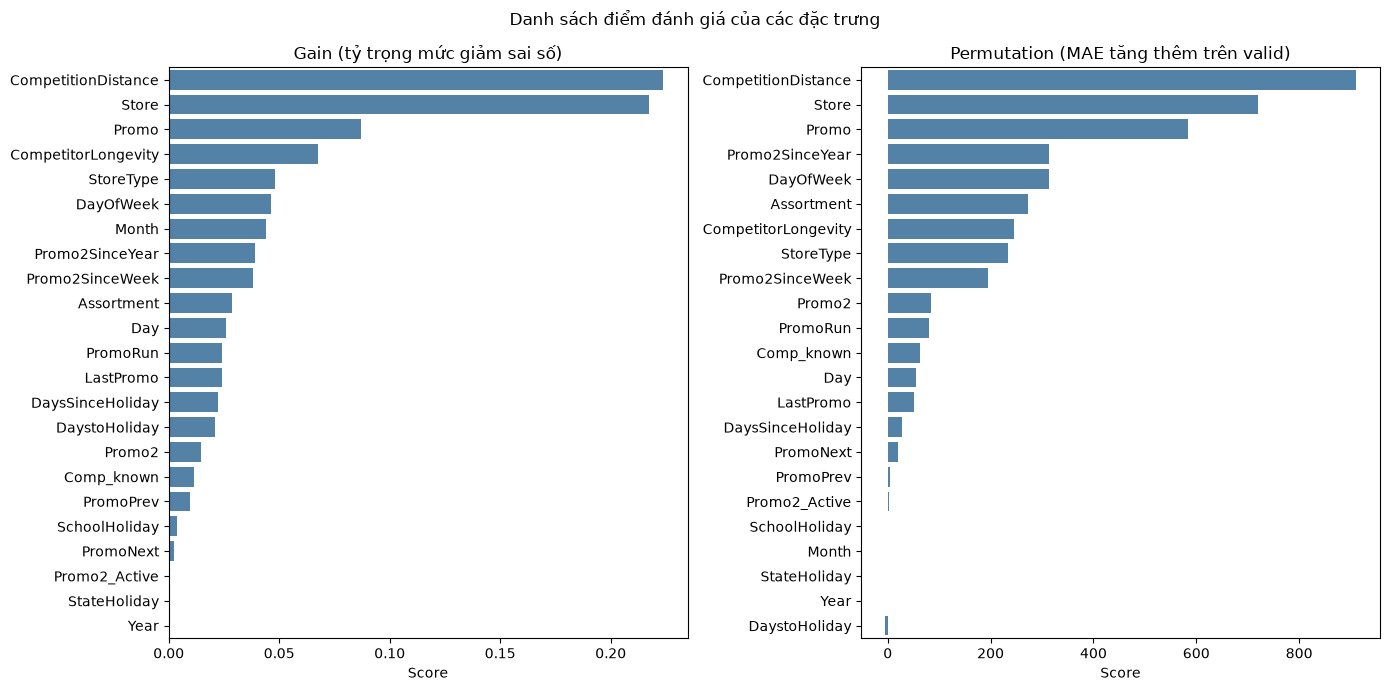

<Figure size 640x480 with 0 Axes>

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

def tidy(s):
    s = s.sort_values(ascending=False)
    return pd.DataFrame({'Feature': s.index.str.replace(r'^(num|cate)__', '', regex=True),
                         'Score': s.values})

panels = [(gain_s, 'Gain (tỷ trọng mức giảm sai số)')]
if perm_s is not None:
    panels.append((perm_s, 'Permutation (MAE tăng thêm trên valid)'))

fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 7), squeeze=False)
for ax, (s, title) in zip(axes[0], panels):
    sns.barplot(data=tidy(s), x='Score', y='Feature', color='steelblue', ax=ax)
    ax.set_title(title); ax.set_ylabel('')
plt.suptitle('Danh sách điểm đánh giá của các đặc trưng')
plt.tight_layout()
plt.show()
save_fig('Danh_sach_diem_danh_gia_cua_cac_dac_trung')

**3.3 Đánh giá các đặc trưng thông quan thang điểm Mutual Information**

Kiểm tra và điền khuyết dữ liệu để kiểm tra chỉ số MI.

In [70]:
missing_values = my_data.isnull().sum()
print(missing_values)

Store                       0
StoreType                   0
Assortment                  0
CompetitionDistance      2186
Promo2                      0
Promo2SinceWeek        423292
Promo2SinceYear        423292
DayOfWeek                   0
Date                        0
Sales                       0
Promo                       0
StateHoliday                0
SchoolHoliday               0
Day                         0
Month                       0
Year                        0
Comp_known                  0
CompetitorLongevity    268600
DaysSinceHoliday           74
DaystoHoliday           57993
PromoPrev                   0
PromoNext                   0
PromoRun                    0
LastPromo                4471
Promo2_Active               0
dtype: int64


In [71]:
medianCD = my_data['CompetitionDistance'].median()
my_data['CompetitionDistance'] = my_data['CompetitionDistance'].fillna(medianCD)
my_data['DaystoHoliday'] = my_data['DaystoHoliday'].fillna(30)
my_data['DaysSinceHoliday'] = my_data['DaysSinceHoliday'].fillna(30)
my_data['LastPromo'] = my_data['LastPromo'].fillna(-1)
my_data['CompetitorLongevity'] = my_data['CompetitorLongevity'].fillna(-1)
my_data['Promo2SinceWeek'] = my_data['Promo2SinceWeek'].fillna(-1)
my_data['Promo2SinceYear'] = my_data['Promo2SinceYear'].fillna(-1)
missing_values = my_data.isnull().sum()
print(missing_values)

Store                  0
StoreType              0
Assortment             0
CompetitionDistance    0
Promo2                 0
Promo2SinceWeek        0
Promo2SinceYear        0
DayOfWeek              0
Date                   0
Sales                  0
Promo                  0
StateHoliday           0
SchoolHoliday          0
Day                    0
Month                  0
Year                   0
Comp_known             0
CompetitorLongevity    0
DaysSinceHoliday       0
DaystoHoliday          0
PromoPrev              0
PromoNext              0
PromoRun               0
LastPromo              0
Promo2_Active          0
dtype: int64


Tính điểm MI cho các đặc trưng của dữ liệu.

In [ ]:
from sklearn.feature_selection import mutual_info_regression
X_train = my_data[my_data['Date'] <= TRAIN_TEST_END]
y_train = X_train['Sales']
X_train = X_train.drop(['Sales' , 'Date'] , axis = 1 )
for colname in X_train.select_dtypes('object'):
    X_train[colname] , _ = X_train[colname].factorize()
discrete_features = X_train.dtypes == int
mi_scores = mutual_info_regression(X_train , y_train , discrete_features = discrete_features)
mi_scores = pd.Series( mi_scores , name = 'MI Scores' , index = X_train.columns)
mi_scores = mi_scores.sort_values( ascending = False)
mi_scores[::3]

C:\Users\Admin\AppData\Local\Temp\ipykernel_18744\4046032544.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for colname in X_train.select_dtypes('object'):


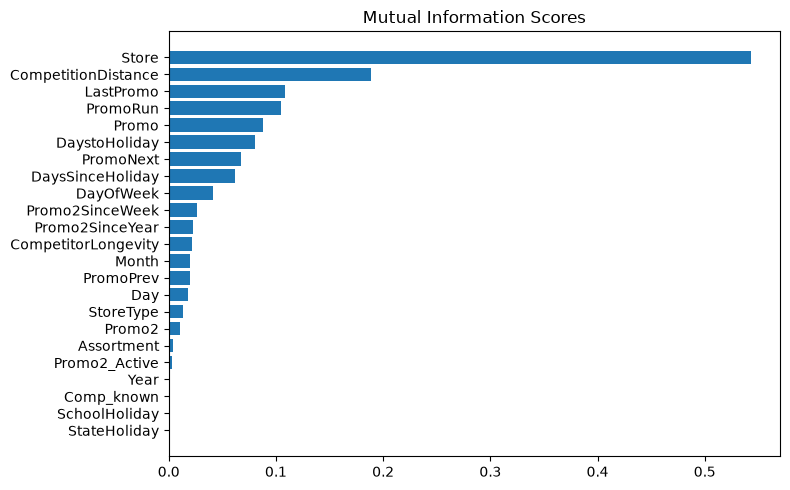

In [ ]:
plt.figure( dpi=100 , figsize = ( 8 , 5 ))
scores = mi_scores.sort_values(ascending = True )
width = np.arange(len(scores))
ticks = list(scores.index)
plt.barh(width , scores)
plt.yticks(width , ticks)
plt.title('Mutual Information Scores')
plt.tight_layout()

**3.4 Kiểm định độ chính xác của mô hình và thử nghiệm thêm xoá một vài đặc trưng**

Tạo dữ liệu để mô hình kiểm nghiệm.

In [ ]:
col_str = ['StoreType', 'Assortment', 'StateHoliday']
my_data[col_str] = my_data[col_str].astype('category')
X_train = my_data[my_data['Date'] <= TRAIN_TEST_END]
y_train = X_train['Sales']
y_train_log = np.log1p(y_train)
X_train = X_train.drop(['Sales' , 'Date'] , axis = 1 )
X_valid = my_data[(my_data['Date'] > TRAIN_TEST_END) & (my_data['Date'] <= VALID_TEST_END)]
y_valid = X_valid['Sales']
y_valid_log = np.log1p(y_valid)
X_valid = X_valid.drop(['Sales' , 'Date'] , axis = 1 )

Tạo và huấn luyện mô hình thuần nhất trên tập X_train

In [ ]:
model_lgb = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.05, max_depth=10,
                              num_leaves=127, n_jobs=-1, random_state=0)
model_lgb.fit(X_train, y_train_log, eval_set=[(X_valid, y_valid_log)],
              callbacks=[lgb.early_stopping(50), lgb.log_evaluation(200)])
display(model_lgb)
best_n = model_lgb.best_iteration_

c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[200]	valid_0's l2: 0.0349322
[400]	valid_0's l2: 0.0255276
[600]	valid_0's l2: 0.0233615
[800]	valid_0's l2: 0.0227862
[1000]	valid_0's l2: 0.0225844
[1200]	valid_0's l2: 0.0224132
Early stopping, best iteration is:
[1156]	valid_0's l2: 0.0224045


,num_leaves,127
,max_depth,10
,learning_rate,0.05
,n_estimators,3000
,random_state,0
,n_jobs,-1
,boosting_type,'gbdt'
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


Đánh giá model thông qua thang đo RMSPE và MAE.

In [ ]:
from sklearn.metrics import mean_absolute_error
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0                      # tránh chia cho 0
    pct = (y_true[mask] - y_pred[mask]) / y_true[mask]
    return np.sqrt(np.mean(pct ** 2))
predict_valid_log = model_lgb.predict(X_valid)
predict_valid = np.expm1(predict_valid_log)
rmspe_valid = rmspe( y_valid , predict_valid)
mae_valid = mean_absolute_error( y_valid , predict_valid )
print('RMSPE: ' , rmspe_valid)
print('MEA: ' , mae_valid )

RMSPE:  0.14321939133933148
MEA:  727.8510479411148


Tạo hàm đo và ghi lại các kết quả khi xoá các đặc trưng.

In [ ]:
import time
import numpy as np, pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings('ignore', module='lightgbm')

results = {}  

class Experiment:
    """Một giai đoạn thí nghiệm: cùng y, cùng tham số, cùng bảng kết quả."""

    DEFAULT_PARAMS = dict(n_estimators=3000, learning_rate=0.1, num_leaves=127,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          n_jobs=-1, verbose=-1)

    def __init__(self, y_train, y_valid, seeds=(0,), params=None, base='Mốc'):
        """y_train, y_valid: DOANH THU THẬT (chưa log). Log được tính bên trong."""
        self.y_train, self.y_valid = y_train, y_valid
        self.y_train_log, self.y_valid_log = np.log1p(y_train), np.log1p(y_valid)
        self.seeds = seeds
        self.params = {**self.DEFAULT_PARAMS, **(params or {})}
        self.base = base
        self.results = {}

    def run(self, name, X_train, X_valid, seeds=None, note=''):
        # Chặn lỗi nhãn lệch dòng ngay từ đầu
        assert len(X_train) == len(self.y_train), f'X_train {len(X_train)} ≠ y_train {len(self.y_train)}'
        assert len(X_valid) == len(self.y_valid), f'X_valid {len(X_valid)} ≠ y_valid {len(self.y_valid)}'

        t0 = time.time()
        rm, ma, its = [], [], []
        for s in (seeds or self.seeds):
            m = lgb.LGBMRegressor(**self.params, random_state=s)      # mô hình MỚI mỗi lần
            m.fit(X_train, self.y_train_log,
                  eval_set=[(X_valid, self.y_valid_log)],
                  callbacks=[lgb.early_stopping(50, verbose=False)])
            p = np.clip(np.expm1(m.predict(X_valid)), 0, None)         # về doanh thu thật
            rm.append(rmspe(self.y_valid, p))
            ma.append(mean_absolute_error(self.y_valid, p))
            its.append(m.best_iteration_)

        self.results[name] = dict(n_feat=X_train.shape[1],
                                  RMSPE=np.mean(rm), RMSPE_std=np.std(rm),
                                  MAE=np.mean(ma), MAE_std=np.std(ma),
                                  cay=int(np.mean(its)), giay=round(time.time() - t0),
                                  ghi_chu=note)
        print(f'{name:<28} RMSPE {np.mean(rm):.4f} ± {np.std(rm):.4f} | MAE {np.mean(ma):.1f}')
        self.last_model = m                     # luôn lưu lại, khi cần thì lấy ra
        return m if return_model else None

    def run_drop(self, X_train, X_valid, cols, **kw):
        """Thử xoá một cột hoặc một nhóm cột."""
        cols = [cols] if isinstance(cols, str) else list(cols)
        return self.run('Xoá ' + ', '.join(cols),
                        X_train.drop(columns=cols), X_valid.drop(columns=cols), **kw)

    def run_add(self, X_train, X_valid, extra_train, extra_valid, name, **kw):
        """Thử thêm cột (DataFrame cùng index với X)."""
        return self.run(name, X_train.join(extra_train), X_valid.join(extra_valid), **kw)

    def summary(self):
        assert self.base in self.results, f'Chưa chạy "{self.base}" trong giai đoạn này'
        res = pd.DataFrame.from_dict(self.results, orient='index')
        b = res.loc[self.base]
        res['ΔRMSPE'] = res['RMSPE'] - b['RMSPE']
        res['ΔMAE'] = res['MAE'] - b['MAE']
        noise = 2 * np.maximum(res['RMSPE_std'], b['RMSPE_std'])      # ngưỡng nhiễu = 2 độ lệch chuẩn
        res['kết luận'] = np.where(res['ΔRMSPE'] < -noise, 'tốt hơn',
                          np.where(res['ΔRMSPE'] > noise, 'tệ hơn', 'không khác (trong nhiễu)'))
        res.loc[self.base, 'kết luận'] = 'mốc'
        return res.sort_values('RMSPE')

    def plot(self, title='Thay đổi so với mốc (âm = tốt hơn)'):
        res = self.summary().drop(index=self.base).sort_values('ΔRMSPE')
        fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * len(res) + 1.5), sharey=True)
        for ax, col, std in [(axes[0], 'ΔRMSPE', 'RMSPE_std'), (axes[1], 'ΔMAE', 'MAE_std')]:
            ax.barh(res.index, res[col], xerr=res[std], color='#8fa3ad', capsize=3)
            ax.axvline(0, color='black', lw=0.8)
            ax.set_title(col)
        fig.suptitle(title)
        plt.tight_layout()
        return fig

    def save(self, path):
        self.summary().to_csv(path)

Thử xoá các đặc trưng không mang lại hữu ích cho mô hình.

Mốc                          RMSPE 0.1441 ± 0.0000 | MAE 756.3
Xoá Year                     RMSPE 0.1441 ± 0.0000 | MAE 756.3
Xoá PromoPrev                RMSPE 0.1455 ± 0.0000 | MAE 741.0
Xoá StateHoliday             RMSPE 0.1417 ± 0.0000 | MAE 724.9
Xoá SchoolHoliday            RMSPE 0.1430 ± 0.0000 | MAE 735.9
Xoá Comp_known               RMSPE 0.1420 ± 0.0000 | MAE 723.2
Xoá PromoNext                RMSPE 0.1439 ± 0.0000 | MAE 740.5
Xoá Promo2_Active            RMSPE 0.1438 ± 0.0000 | MAE 736.7
Xoá Promo2SinceWeek          RMSPE 0.1421 ± 0.0000 | MAE 739.7
Xoá Promo2SinceYear          RMSPE 0.1424 ± 0.0000 | MAE 733.2
Xoá CompetitorLongevity      RMSPE 0.1433 ± 0.0000 | MAE 725.0


,n_feat,RMSPE,RMSPE_std,MAE,MAE_std,cay,giay,ghi_chu,ΔRMSPE,ΔMAE,kết luận
Xoá StateHoliday,22,0.141675,0.0,724.926113,0.0,694,26,,-0.002396,-31.376313,tốt hơn
Xoá Comp_known,22,0.142022,0.0,723.202555,0.0,747,32,,-0.002049,-33.099871,tốt hơn
Xoá Promo2SinceWeek,22,0.142080,0.0,739.663278,0.0,578,58,,-0.001990,-16.639148,tốt hơn
Xoá Promo2SinceYear,22,0.142449,0.0,733.187979,0.0,427,48,,-0.001621,-23.114447,tốt hơn
Xoá SchoolHoliday,22,0.142973,0.0,735.873500,0.0,641,33,,-0.001098,-20.428927,tốt hơn
Xoá CompetitorLongevity,22,0.143252,0.0,725.013773,0.0,359,46,,-0.000819,-31.288653,tốt hơn
Xoá Promo2_Active,22,0.143845,0.0,736.673283,0.0,471,47,,-0.000226,-19.629143,tốt hơn
Xoá PromoNext,22,0.143886,0.0,740.480886,0.0,455,29,,-0.000185,-15.821541,tốt hơn
Mốc,23,0.144071,0.0,756.302426,0.0,388,23,,0.000000,0.000000,mốc
Xoá Year,22,0.144071,0.0,756.302426,0.0,388,20,,0.000000,0.000000,không khác (trong nhiễu)


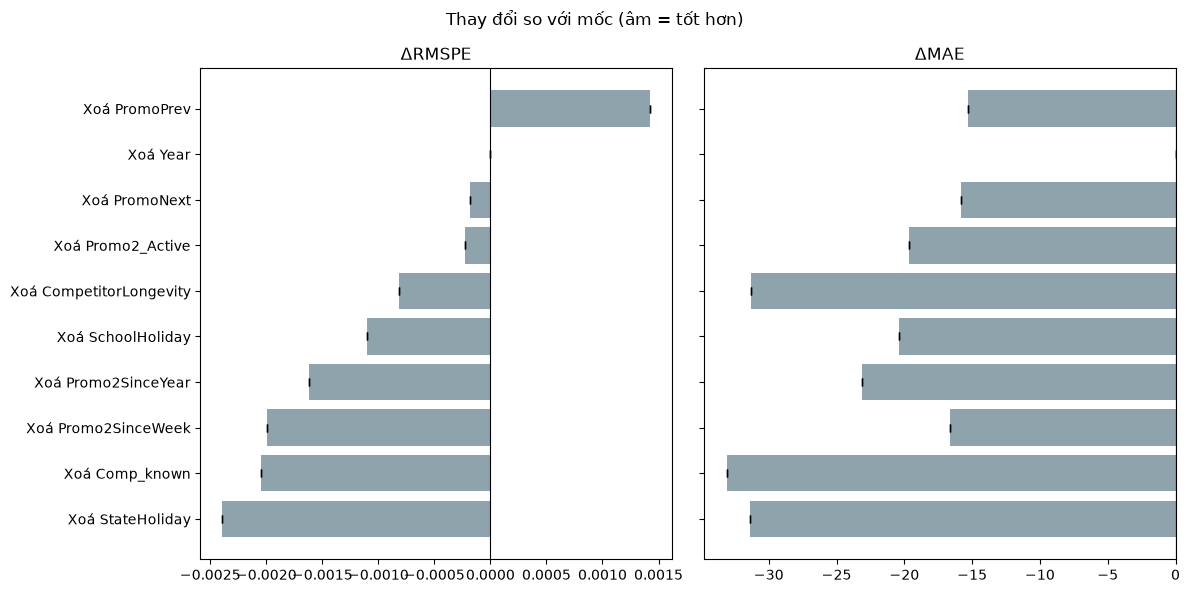

In [ ]:
delete_test_feature = ['Year' , 'PromoPrev' , 'StateHoliday' , 'SchoolHoliday' ,'Comp_known' , 'PromoNext' , 'Promo2_Active',
                       'Promo2SinceWeek' , 'Promo2SinceYear' , 'CompetitorLongevity']
exp_feat = Experiment(y_train, y_valid, seeds=(0,))
exp_feat.run('Mốc', X_train, X_valid)
for feature_delete in delete_test_feature:
    exp_feat.run_drop(X_train , X_valid , feature_delete)
display(exp_feat.summary())
exp_feat.plot(); plt.show()
# exp_feat.save('results/ablation_features.csv')

Xoá các đặc trưng gây ra nhiễu hoặc không mang lại thông tin cho mô hình học máy.

In [ ]:
cols_delete = ['Year' , 'StateHoliday' , 'SchoolHoliday' , 'Promo2SinceYear' , 'Comp_known' ] 
exp_feat.run_drop(X_train , X_valid , cols_delete );

Xoá Year, StateHoliday, SchoolHoliday, Promo2SinceYear, Comp_known RMSPE 0.1424 ± 0.0000 | MAE 734.0


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


In [ ]:
my_data = my_data.drop(columns = cols_delete)
my_data.head()

,Store,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,DayOfWeek,Date,Sales,Promo,Day,Month,CompetitorLongevity,DaysSinceHoliday,DaystoHoliday,PromoPrev,PromoNext,PromoRun,LastPromo,Promo2_Active
1,1,c,a,1270.0,0,-1.0,3,2013-01-02,5530,0,2,1,52.0,1.0,86.0,0,0,0,-1.0,0
2,1,c,a,1270.0,0,-1.0,4,2013-01-03,4327,0,3,1,52.0,2.0,85.0,0,0,0,-1.0,0
3,1,c,a,1270.0,0,-1.0,5,2013-01-04,4486,0,4,1,52.0,3.0,84.0,0,0,0,-1.0,0
4,1,c,a,1270.0,0,-1.0,6,2013-01-05,4997,0,5,1,52.0,4.0,83.0,0,0,0,-1.0,0
6,1,c,a,1270.0,0,-1.0,1,2013-01-07,7176,1,7,1,52.0,6.0,81.0,0,1,1,0.0,0


**3.5 Phân cụm các đặc trưng có liên quan**

Tạo lại tập mẫu và kết quả mô hình dự đoán trước khi thêm cụm.

In [ ]:
X_train = my_data[my_data['Date'] <= TRAIN_TEST_END]
y_train = X_train['Sales']
y_train_log = np.log1p(y_train)
X_train = X_train.drop(['Sales' , 'Date'] , axis = 1 )
X_valid = my_data[(my_data['Date'] > TRAIN_TEST_END) & (my_data['Date'] <= VALID_TEST_END)]
y_valid = X_valid['Sales']
y_valid_log = np.log1p(y_valid)
X_valid = X_valid.drop(['Sales' , 'Date'] , axis = 1 )

In [ ]:
exp_clu = Experiment(y_train , y_valid , seeds=(0,))
exp_clu.run('Mốc' , X_train , X_valid);

Mốc                          RMSPE 0.1424 ± 0.0000 | MAE 734.0


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


Phân cụm các đặc trưng theo mức cạnh tranh với đối thủ.

In [ ]:
features = ['CompetitionDistance', 'CompetitorLongevity']
X_train_clu = X_train[X_train['CompetitionDistance'] > 0]
store_feat = X_train_clu.groupby('Store').agg(
    CompetitionDistance = ('CompetitionDistance', 'first'),   # cố định theo cửa hàng
    CompetitorLongevity = ('CompetitorLongevity', 'max'),     # tăng dần theo thời gian → lấy giá trị cuối giai đoạn train
)
# Giảm ảnh hưởng của giá trị cực lớn (999999, đối thủ mở từ năm 1900...)
store_feat['CompetitionDistance'] = np.log1p(store_feat['CompetitionDistance'])
store_feat['CompetitorLongevity'] = np.log1p(store_feat['CompetitorLongevity'].clip(lower=0))

print(store_feat.shape)      # phải ra (1115, 3) hoặc gần đó
store_feat.head()

(1115, 2)


,CompetitionDistance,CompetitorLongevity
Store,,
1,7.147559,4.158883
2,6.347389,4.304065
3,9.556126,4.442651
4,6.431331,3.951244
5,10.305982,0.000000


2    0.461
3    0.462
4    0.474
5    0.459
6    0.453
7    0.422
8    0.442
dtype: float64

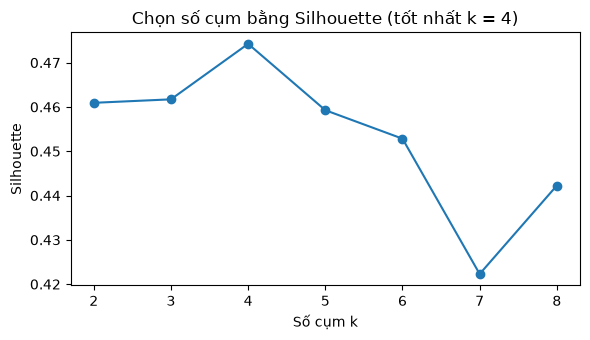

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

store_feat_scale = StandardScaler().fit_transform(store_feat[features])

silhouette = pd.Series({
    k: silhouette_score(store_feat_scale, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(store_feat_scale))
    for k in range(2, 9)
})
best_k = silhouette.idxmax()

plt.figure(figsize=(6, 3.5))
silhouette.plot(marker='o')
plt.xlabel('Số cụm k')
plt.ylabel('Silhouette')
plt.title(f'Chọn số cụm bằng Silhouette (tốt nhất k = {best_k})')
save_fig('silhouette')
silhouette.round(3)

In [ ]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=0)
store_feat['Cluster_comp'] = kmeans.fit_predict(store_feat_scale)

for X in (X_train, X_valid ):          # bỏ X_test nếu chưa tạo
    X['Cluster_comp'] = X['Store'].map(store_feat['Cluster_comp']).fillna(-1).astype(int)

print(store_feat['Cluster_comp'].value_counts().sort_index())

Cluster_comp
0    346
1    202
2    311
3    256
Name: count, dtype: int64


In [ ]:
summary = store_feat.copy()
summary['CompetitionDistance_m'] = np.expm1(summary['CompetitionDistance']).round(0)   # đổi về mét
summary['CompetitorLongevity_thang'] = np.expm1(summary['CompetitorLongevity']).round(0)

display(summary.groupby('Cluster_comp').agg(
    khoang_cach_TV  = ('CompetitionDistance_m', 'median'),
    so_thang_DT_TV  = ('CompetitorLongevity_thang', 'median'),
))

,khoang_cach_TV,so_thang_DT_TV
Cluster_comp,,
0,5240.0,63.0
1,450.0,0.0
2,5760.0,0.0
3,590.0,66.5


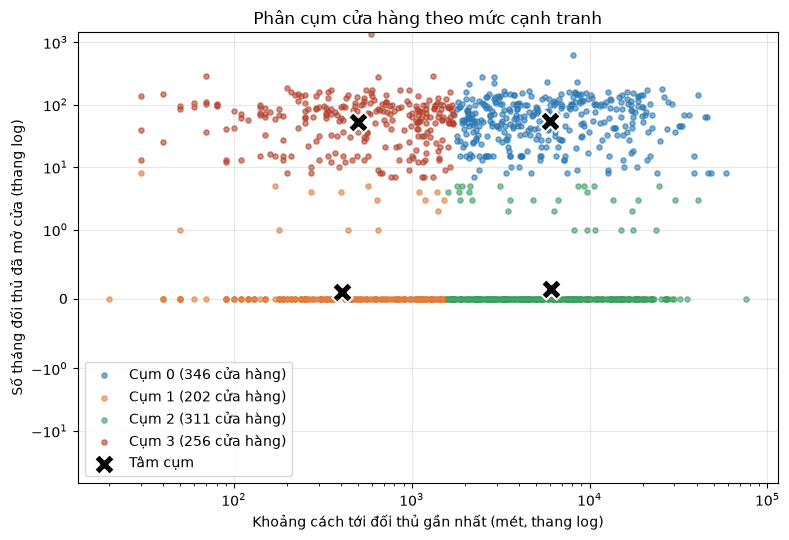

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))

colors = ['#2a78b5', '#e07b39', '#3a9e5f', '#b5402a']   # đủ cho tối đa 4 cụm
for c in sorted(store_feat['Cluster_comp'].unique()):
    part = store_feat[store_feat['Cluster_comp'] == c]
    ax.scatter(np.expm1(part['CompetitionDistance']),           # đổi về mét
               np.expm1(part['CompetitorLongevity']),            # đổi về tháng
               s=14, alpha=0.6, color=colors[c],
               label=f'Cụm {c} ({len(part)} cửa hàng)')

# Tâm cụm (KMeans học trên dữ liệu đã chuẩn hoá → đổi ngược về đơn vị gốc)
scaler = StandardScaler().fit(store_feat[features])
centers = scaler.inverse_transform(kmeans.cluster_centers_)
ax.scatter(np.expm1(centers[:, 0]), np.expm1(centers[:, 1]),
           marker='X', s=220, color='black', edgecolor='white', linewidth=1.5, label='Tâm cụm')

ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=1)        # trục y có số 0 nên dùng symlog thay vì log
ax.set_xlabel('Khoảng cách tới đối thủ gần nhất (mét, thang log)')
ax.set_ylabel('Số tháng đối thủ đã mở cửa (thang log)')
ax.set_title('Phân cụm cửa hàng theo mức cạnh tranh')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('cluster_competition_scatter')
plt.show()

Chạy thử nghiệm độ hiệu quả của phân cụm.

In [ ]:
exp_clu.run('Thêm cụm liên quan đến đối thủ' , X_train , X_valid );

Thêm cụm liên quan đến đối thủ RMSPE 0.1417 ± 0.0000 | MAE 723.1


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


Phân cụm theo hành vi tiêu dùng của khách hàng.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

tr = my_data[my_data['Date'] <= '2013-12-31']          # CHỈ dùng giai đoạn train

profile = pd.DataFrame({
    'sales_mean':   np.log1p(g['Sales'].mean()),
    'sales_cv':     g['Sales'].std() / g['Sales'].mean(),
    'promo_lift':   tr[tr.Promo == 1].groupby('Store')['Sales'].mean()
                    / tr[tr.Promo == 0].groupby('Store')['Sales'].mean(),
    'mon_sat':      tr[tr.DayOfWeek == 1].groupby('Store')['Sales'].mean()
                    / tr[tr.DayOfWeek == 6].groupby('Store')['Sales'].mean(),
    'dec_lift':     tr[tr.Month == 12].groupby('Store')['Sales'].mean() / g['Sales'].mean(),
    'basket':       g['Sales'].sum() / g['Customers'].sum(),
    'open_sunday':  tr[tr.DayOfWeek == 7].groupby('Store').size()
                    .reindex(profile_index := g.size().index, fill_value=0) > 0,
}).fillna(1)   # cửa hàng thiếu dữ liệu một nhóm → coi như không chênh lệch

profile_scale = StandardScaler().fit_transform(profile)
for k in range(2, 9):
    lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(profile_scale)
    print(k, round(silhouette_score(profile_scale, lab), 3))

2 0.646
3 0.283
4 0.211
5 0.214
6 0.217
7 0.216
8 0.214


Mô tả lại từng cụm trong báo cáo.

In [ ]:
profile['Cluster_behavior'] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(profile_scale)
display(profile.groupby('Cluster_behavior').mean().round(2))
display(profile['Cluster_behavior'].value_counts())

,sales_mean,sales_cv,promo_lift,mon_sat,dec_lift,basket,open_sunday
Cluster_behavior,,,,,,,
0,8.65,0.53,1.33,1.29,1.50,9.95,0.0
1,8.90,0.36,1.28,1.39,1.19,6.94,1.0
2,8.45,0.59,1.61,2.22,1.53,9.15,0.0


Cluster_behavior
0    781
2    301
1     33
Name: count, dtype: int64

In [ ]:
X_train = pd.merge(X_train , profile , how='left' , on ='Store')
X_valid = pd.merge(X_valid , profile , how='left' , on ='Store')
X_train.head()

,Store,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,DayOfWeek,Promo,Day,Month,...,Promo2_Active,Cluster_comp,sales_mean,sales_cv,promo_lift,mon_sat,dec_lift,basket,open_sunday,Cluster_behavior
0,1,c,a,1270.0,0,-1.0,3,0,2,1,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0
1,1,c,a,1270.0,0,-1.0,4,0,3,1,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0
2,1,c,a,1270.0,0,-1.0,5,0,4,1,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0
3,1,c,a,1270.0,0,-1.0,6,0,5,1,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0
4,1,c,a,1270.0,0,-1.0,1,1,7,1,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0


Kiểm tra độ hữu ích của cụm.

In [ ]:
exp_clu.run('Thêm cụm hành vi tiêu dùng khách hàng' , X_train , X_valid )

Thêm cụm hành vi tiêu dùng khách hàng RMSPE 0.1326 ± 0.0000 | MAE 688.9


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


Kết quả phân cụm.

,n_feat,RMSPE,RMSPE_std,MAE,MAE_std,cay,giay,ghi_chu,ΔRMSPE,ΔMAE,kết luận
Thêm cụm hành vi tiêu dùng khách hàng,27,0.132582,0.0,688.918428,0.0,28,14,,-0.009816,-45.097666,tốt hơn
Thêm cụm liên quan đến đối thủ,19,0.141747,0.0,723.136777,0.0,648,35,,-0.000651,-10.879317,tốt hơn
Mốc,18,0.142398,0.0,734.016094,0.0,452,34,,0.000000,0.000000,mốc


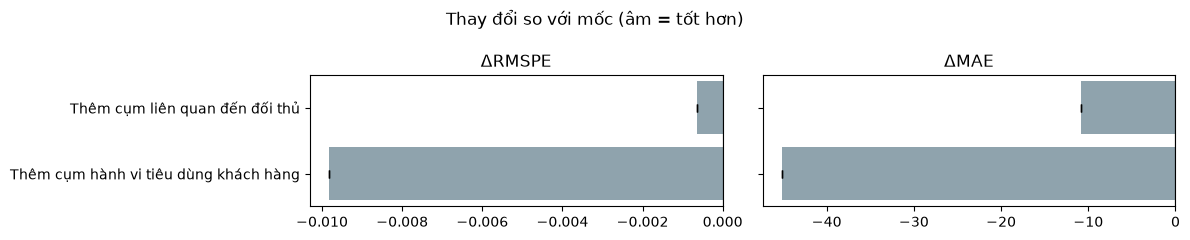

In [ ]:
display(exp_clu.summary())
exp_clu.plot(); plt.show()

Thêm các cụm vào dữ liệu.

In [ ]:
my_data['Cluster_comp'] = my_data['Store'].map(store_feat['Cluster_comp']).fillna(-1).astype(int)
my_data = pd.merge(my_data , profile , how='left' , on ='Store')
my_data.head()

,Store,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,DayOfWeek,Date,Sales,Promo,...,Promo2_Active,Cluster_comp,sales_mean,sales_cv,promo_lift,mon_sat,dec_lift,basket,open_sunday,Cluster_behavior
0,1,c,a,1270.0,0,-1.0,3,2013-01-02,5530,0,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0
1,1,c,a,1270.0,0,-1.0,4,2013-01-03,4327,0,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0
2,1,c,a,1270.0,0,-1.0,5,2013-01-04,4486,0,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0
3,1,c,a,1270.0,0,-1.0,6,2013-01-05,4997,0,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0
4,1,c,a,1270.0,0,-1.0,1,2013-01-07,7176,1,...,0,3,8.280636,0.510788,1.232385,1.068059,1.532975,8.437366,False,0


**3.6 Xử lý chuỗi thời gian của dữ liệu và tái tạo mô hình hybrid trên tập thử nghiệm**

Tạo lại dữ liệu mẫu

In [ ]:
X_train = my_data[my_data['Date'] <= TRAIN_TEST_END]
y_train = X_train['Sales']
y_train_log = np.log1p(y_train)
X_train = X_train.drop(['Sales' , 'Date'] , axis = 1 )
X_valid = my_data[(my_data['Date'] > TRAIN_TEST_END) & (my_data['Date'] <= VALID_TEST_END)]
y_valid = X_valid['Sales']
y_valid_log = np.log1p(y_valid)
X_valid = X_valid.drop(['Sales' , 'Date'] , axis = 1 )

Kết quả mô hình dự đoán trước khi xử lý chuỗi thời gian.

In [ ]:
exp_time = Experiment(y_train , y_valid , seeds=(0,))
exp_time.run('Mốc' , X_train , X_valid)

Mốc                          RMSPE 0.1326 ± 0.0000 | MAE 688.9


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


Kiểm định độ hiệu quả cửa biến lag 1 và lag 8 mang lại cho mô hình.

In [ ]:
my_data_lags = my_data.copy()
my_data_lags['lag_1'] = my_data_lags.groupby('Store')['Sales'].shift(1)
my_data_lags['lag_8'] = my_data_lags.groupby('Store')['Sales'].shift(8)
print(my_data_lags[['Date', 'Store', 'lag_1', 'lag_8']].head())

        Date  Store   lag_1  lag_8
0 2013-01-02      1     NaN    NaN
1 2013-01-03      1  5530.0    NaN
2 2013-01-04      1  4327.0    NaN
3 2013-01-05      1  4486.0    NaN
4 2013-01-07      1  4997.0    NaN


In [ ]:
exp_time.run('Thêm lag_1 và lag_8' , my_data_lags[my_data_lags['Date'] <= TRAIN_TEST_END].drop(['Sales' , 'Date'] , axis = 1 ) , 
               my_data_lags[(my_data_lags['Date'] > TRAIN_TEST_END) & (my_data_lags['Date'] <= VALID_TEST_END)].drop(['Sales' , 'Date'] , axis = 1 ))

Thêm lag_1 và lag_8          RMSPE 0.1128 ± 0.0000 | MAE 564.6


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


Khi thêm doanh thu của 1 và 8 ngày bán trước, RMSPE giảm từ 0,1326 xuống 0,1128 (giảm khoảng 15%), MAE còn 564,6 (so với [MAE mốc] của mốc). Đây là mức cải thiện lớn nhất trong các thí nghiệm, phù hợp với phân tích PACF: doanh thu hôm nay liên quan chặt chẽ nhất với doanh thu của ngày bán ngay trước đó. Tuy nhiên, đặc trưng này chỉ dùng được khi dự báo ngày kế tiếp, vì phải biết doanh thu hôm qua.

Kiểm định độ hiệu quả của các biến lag theo horizon có thể đưa vào mô hình.

In [ ]:
my_data_lags = my_data_lags.drop(columns = ['lag_1', 'lag_8'])
my_data_lags['lag_49'] = my_data_lags.groupby('Store')['Sales'].shift(49)
my_data_lags['lag_56'] = my_data_lags.groupby('Store')['Sales'].shift(56)
my_data_lags['lag_63'] = my_data_lags.groupby('Store')['Sales'].shift(63)
print(my_data_lags[['Date', 'Store', 'lag_49' ,'lag_56' , 'lag_63']].head())

        Date  Store  lag_49  lag_56  lag_63
0 2013-01-02      1     NaN     NaN     NaN
1 2013-01-03      1     NaN     NaN     NaN
2 2013-01-04      1     NaN     NaN     NaN
3 2013-01-05      1     NaN     NaN     NaN
4 2013-01-07      1     NaN     NaN     NaN


In [ ]:
exp_time.run('Thêm lag 49 56 63' , my_data_lags[my_data_lags['Date'] <= TRAIN_TEST_END].drop(['Sales' , 'Date'] , axis = 1 ) , 
               my_data_lags[(my_data_lags['Date'] > TRAIN_TEST_END) & (my_data_lags['Date'] <= VALID_TEST_END)].drop(['Sales' , 'Date'] , axis = 1 ))

Thêm lag 49 56 63            RMSPE 0.1249 ± 0.0000 | MAE 621.7


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


Với các độ trễ dài (49, 56 và 63 ngày bán), RMSPE giảm xuống 0,1249 (khoảng 6% so với mốc), MAE là 621,7. Mức cải thiện nhỏ hơn nhiều so với lag_1, lag_8, vì thông tin cách xa hơn 6 tuần ít liên quan tới doanh thu hiện tại. Dù vậy, các độ trễ này đều lớn hơn 42 ngày, nên mô hình vẫn dùng được khi dự báo trước 6 tuần, đúng yêu cầu gốc của Rossmann, và vẫn tốt hơn so với không dùng độ trễ.

Đưa trend và mùa vụ cho mô hình học các đặc trưng về thời gian.

In [ ]:
import re
X_fourier.columns = [re.sub(r'[^0-9a-zA-Z_]', '_', c) for c in X_fourier.columns]
print(X_fourier.columns.tolist())

['const', 'trend', 's_2_7_', 's_5_7_', 'sin_1_freq_YE_DEC_', 'cos_1_freq_YE_DEC_', 'sin_2_freq_YE_DEC_', 'cos_2_freq_YE_DEC_', 'sin_3_freq_YE_DEC_', 'cos_3_freq_YE_DEC_', 'sin_4_freq_YE_DEC_', 'cos_4_freq_YE_DEC_', 'sin_5_freq_YE_DEC_', 'cos_5_freq_YE_DEC_', 'sin_6_freq_YE_DEC_', 'cos_6_freq_YE_DEC_', 'sin_7_freq_YE_DEC_', 'cos_7_freq_YE_DEC_', 'sin_8_freq_YE_DEC_', 'cos_8_freq_YE_DEC_', 'sin_9_freq_YE_DEC_', 'cos_9_freq_YE_DEC_', 'sin_10_freq_YE_DEC_', 'cos_10_freq_YE_DEC_', 'sin_1_freq_W_SUN_', 'cos_1_freq_W_SUN_', 'sin_2_freq_W_SUN_', 'cos_2_freq_W_SUN_']


In [ ]:
my_data_fourier = pd.merge(my_data , X_fourier , how= 'left' , on = 'Date')

In [ ]:
exp_time.run('Học xu hướng mùa vụ' , my_data_fourier[my_data_fourier['Date'] <= TRAIN_TEST_END].drop(['Sales' , 'Date'] , axis = 1 ) , 
               my_data_fourier[(my_data_fourier['Date'] > TRAIN_TEST_END) & (my_data_fourier['Date'] <= VALID_TEST_END)].drop(['Sales' , 'Date'] , axis = 1 ))

Học xu hướng mùa vụ          RMSPE 0.2348 ± 0.0000 | MAE 1154.0


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


Khi thêm các đặc trưng xu hướng và mùa vụ (trend, biến giả thứ trong tuần, sóng Fourier), kết quả xấu đi rõ rệt: RMSPE tăng lên 0,2348 (tăng khoảng 77% so với mốc) và MAE lên 1.154,0. Nguyên nhân chính là cột trend: mô hình cây không kéo dài được xu hướng ra ngoài khoảng đã học, nên mọi ngày trong tập kiểm tra đều rơi vào nhánh của những ngày cuối tập huấn luyện. Các biến giả thứ trong tuần cũng trùng thông tin với DayOfWeek nên không bổ sung gì thêm.

Kết hợp các biến đặc trưng về thời gian cho mô hình học để xác định độ hữu quả của chuỗi thời gian cho mô hình học máy.

In [ ]:
my_data_time_series = pd.merge(my_data_lags, X_fourier, how='left', on='Date')
my_data_time_series.head()

,Store,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,DayOfWeek,Date,Sales,Promo,...,sin_8_freq_YE_DEC_,cos_8_freq_YE_DEC_,sin_9_freq_YE_DEC_,cos_9_freq_YE_DEC_,sin_10_freq_YE_DEC_,cos_10_freq_YE_DEC_,sin_1_freq_W_SUN_,cos_1_freq_W_SUN_,sin_2_freq_W_SUN_,cos_2_freq_W_SUN_
0,1,c,a,1270.0,0,-1.0,3,2013-01-02,5530,0,...,0.137279,0.990532,0.154309,0.988023,0.171293,0.985220,0.974928,-0.222521,-0.433884,-0.900969
1,1,c,a,1270.0,0,-1.0,4,2013-01-03,4327,0,...,0.271958,0.962309,0.304921,0.952378,0.337523,0.941317,0.433884,-0.900969,-0.781831,0.623490
2,1,c,a,1270.0,0,-1.0,5,2013-01-04,4486,0,...,0.401488,0.915864,0.448229,0.893919,0.493776,0.869589,-0.433884,-0.900969,0.781831,0.623490
3,1,c,a,1270.0,0,-1.0,6,2013-01-05,4997,0,...,0.523416,0.852078,0.580800,0.814046,0.635432,0.772157,-0.974928,-0.222521,0.433884,-0.900969
4,1,c,a,1270.0,0,-1.0,1,2013-01-07,7176,1,...,0.735417,0.677615,0.801361,0.598181,0.858764,0.512371,0.000000,1.000000,0.000000,1.000000


In [ ]:
exp_time.run('Thêm cả lag và xu hướng mùa vụ' , 
               my_data_time_series[my_data_time_series['Date'] <= TRAIN_TEST_END].drop(['Sales' , 'Date'] , axis = 1 ) , 
               my_data_time_series[(my_data_time_series['Date'] > TRAIN_TEST_END) & (my_data_time_series['Date'] <= VALID_TEST_END)].drop(['Sales' , 'Date'] , axis = 1 ))

Thêm cả lag và xu hướng mùa vụ RMSPE 0.2297 ± 0.0000 | MAE 1118.2


,num_leaves,127
,n_estimators,3000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,0
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,learning_rate,0.1


Khi kết hợp cả hai nhóm, RMSPE là 0,2297 (tăng khoảng 73% so với mốc) và MAE là 1.118,2. Kết quả chỉ tốt hơn một chút so với chỉ thêm xu hướng mùa vụ và vẫn kém xa mốc. Điều này cho thấy tác động tiêu cực của các đặc trưng thời gian lấn át hoàn toàn lợi ích của độ trễ.

Thống kê kết quả đạt được sau khi xử lý chuỗi thời gian.

,n_feat,RMSPE,RMSPE_std,MAE,MAE_std,cay,giay,ghi_chu,ΔRMSPE,ΔMAE,kết luận
Thêm lag_1 và lag_8,29,0.112813,0.0,564.586387,0.0,267,40,,-0.019768,-124.332042,tốt hơn
Thêm lag 49 56 63,30,0.124945,0.0,621.657102,0.0,73,17,,-0.007637,-67.261327,tốt hơn
Mốc,27,0.132582,0.0,688.918428,0.0,28,13,,0.000000,0.000000,mốc
Thêm cả lag và xu hướng mùa vụ,58,0.229665,0.0,1118.163681,0.0,251,80,,0.097084,429.245252,tệ hơn
Học xu hướng mùa vụ,55,0.234776,0.0,1154.046530,0.0,86,32,,0.102194,465.128101,tệ hơn


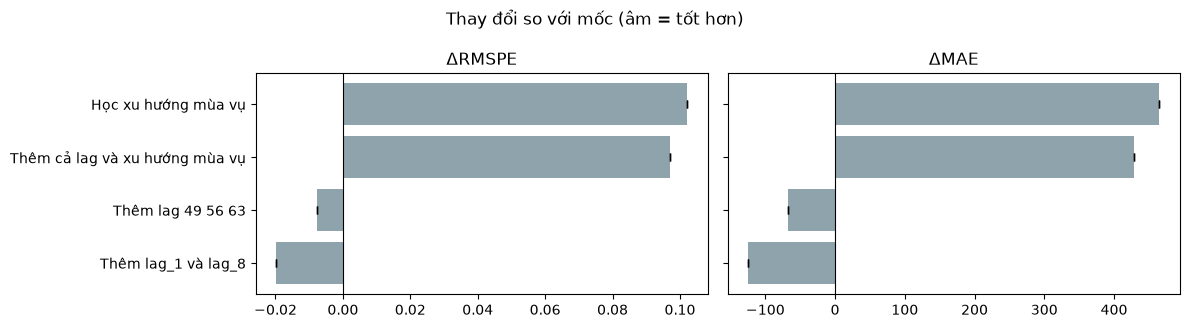

In [ ]:
display(exp_time.summary())
exp_time.plot(); plt.show()

Thêm các đặc trưng có ích vào dữ liệu và một số đặc trưng cần cho phần tiếp theo.

In [ ]:
my_data['lag_49'] = my_data.groupby('Store')['Sales'].shift(49)
my_data['lag_56'] = my_data.groupby('Store')['Sales'].shift(56)
my_data['lag_63'] = my_data.groupby('Store')['Sales'].shift(63)

my_lags = pd.DataFrame(index=y_deseason.index)
my_lags['lag_49_resid'] = y_deseason.shift(49).values
my_lags['lag_56_resid'] = y_deseason.shift(56).values
my_lags['lag_63_resid'] = y_deseason.shift(63).values
my_lags = my_lags.reset_index()
if 'index' in my_lags.columns:
    my_lags = my_lags.rename(columns={'index': 'Date'})
my_data = pd.merge(my_data, my_lags, how='left', on='Date')
print(my_data[['Date', 'Store', 'lag_49' ,'lag_56' , 'lag_63' , 'lag_49_resid' ,'lag_56_resid' , 'lag_63_resid']].head())

        Date  Store  lag_49  lag_56  lag_63  lag_49_resid  lag_56_resid  \
0 2013-01-02      1     NaN     NaN     NaN           NaN           NaN   
1 2013-01-03      1     NaN     NaN     NaN           NaN           NaN   
2 2013-01-04      1     NaN     NaN     NaN           NaN           NaN   
3 2013-01-05      1     NaN     NaN     NaN           NaN           NaN   
4 2013-01-07      1     NaN     NaN     NaN           NaN           NaN   

   lag_63_resid  
0           NaN  
1           NaN  
2           NaN  
3           NaN  
4           NaN  


**Nhận xét:** Trong các đặc trưng chuỗi thời gian, độ trễ của doanh thu có tác dụng rõ nhất. Độ trễ ngắn (lag_1, lag_8) giảm RMSPE khoảng 15% nhưng chỉ phù hợp cho dự báo ngày kế tiếp. Độ trễ dài (49, 56, 63 ngày) giảm khoảng 6% và phù hợp cho dự báo 6 tuần. Ngược lại, xu hướng và sóng Fourier làm RMSPE của LightGBM tăng hơn 70%, vì mô hình cây không ngoại suy được xu hướng, và thông tin mùa vụ đã được thể hiện qua DayOfWeek, Month và các đặc trưng ngày lễ. Vì vậy, nhóm đặc trưng xu hướng và mùa vụ chỉ nên dùng cho phần hồi quy tuyến tính trong mô hình lai; LightGBM chỉ nên nhận các đặc trưng độ trễ.

Lưu lại dữ liệu.

In [ ]:
my_data.to_csv(PROCESSED_DIR / 'rossmann_add_features.csv', index=False)
print('Đã lưu', PROCESSED_DIR / 'rossmann_add_features.csv')
my_data.to_csv(PROCESSED_DIR / 'rossmann_data_timeseries.csv', index=False)
print('Đã lưu', PROCESSED_DIR / 'rossmann_data_timeseries.csv')

Đã lưu data\processed\rossmann_add_features.csv
Đã lưu data\processed\rossmann_data_timeseries.csv
